# 2. Modelación
Importa el pipeline y realiza entrenamiento y evaluación de modelos, usando las semillas fijadas (random_state=42).

Este notebook ejecuta `src/pipeline.py` y `src/train.py` y luego complementa los resultados con métricas adicionales (precision, PR-AUC, umbral, recall por género, importancia y K-Means).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.makedirs(os.path.join("output", "graficos"), exist_ok=True)

In [2]:
from src.pipeline import run as run_pipeline
from src.train import run as run_train

print("Ejecutando Pipeline (Raw & Processed Split)...")
res_pipeline = run_pipeline()

print("\nEjecutando Modelamiento (Semillas Reproducibles)...")
res_train = run_train()

Ejecutando Pipeline (Raw & Processed Split)...
PIPELINE - Preprocesamiento Spotify (Raw & Processed)
[pipeline] Cargando raw data...


[pipeline] Eliminando nulos criticos...
[pipeline] Construyendo song_key para el split (artists + track_name)...
[pipeline] Agrupando generos y calculando max popularity por track_id...


[pipeline] Aplicando MultiLabelBinarizer para generos...


[pipeline] Canciones unicas: 89740. Columnas genre_*: 114
[pipeline] Haciendo split agrupado (GroupShuffleSplit) sobre song_key...


[pipeline] Raw Train: 71711, Raw Test: 18029
[pipeline] Aplicando transformaciones a Train...
[pipeline] Umbral de popularidad (P80) calculado en TRAIN: 52.0
[pipeline] Aplicando transformaciones a Test...
[pipeline] Guardando datos procesados...


...

[train] X_train: (71711, 128) | Hit rate train: 21.0%

[train] Entrenando: Regresion Logistica ...


  AUC CV: 0.8380 | Gap CV: 0.0028 | 57.3s

[train] Entrenando: Random Forest ...


  AUC CV: 0.8215 | Gap CV: 0.0205 | 129.2s

[train] Entrenando: HistGradientBoosting ...


  AUC CV: 0.8569 | Gap CV: 0.0289 | 60.0s

                      auc_cv  auc_train_cv  gap_auc_cv   f1_cv  recall_cv  precision_cv
Regresion Logistica   0.8380        0.8409      0.0028  0.5643     0.8050        0.4344
Random Forest         0.8215        0.8420      0.0205  0.5376     0.7372        0.4232
HistGradientBoosting  0.8569        0.8858      0.0289  0.5721     0.8260        0.4376

[train] Mejor modelo por AUC en CV: HistGradientBoosting
[train] Ablacion de genero sobre HistGradientBoosting ...


[train] AUC CV con genero: 0.8569 | sin genero: 0.6948 | aporte: +0.1620


## 1. Comparación de modelos en test
Además del AUC se reportan precision, F1 y PR-AUC: con `class_weight="balanced"` el recall sube a costa de la precisión, y mostrar solo el recall haría ver el resultado mejor de lo que es.

In [3]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score
from src.pipeline import FEATURES_SCALE
from src.test import run as run_test
from src.metricas import tabla_comparativa, verificar_kpis
from src import graficos as gr

X_train = pd.read_csv("data/processed/train/X_train.csv")
X_test = pd.read_csv("data/processed/test/X_test.csv")
y_test = pd.read_csv("data/processed/test/y_test.csv").squeeze()
raw_test = pd.read_csv("data/raw/test/raw_test.csv")   # mismo orden que X_test

# La evaluación final (AUC, precision, recall, F1, PR-AUC, gap, lift y KPIs) vive solo en src/test.py;
# aquí se reutiliza su resultado, que también deja resultados_test.csv y kpis_cumplidos.csv.
res = run_test()
modelos = {n: joblib.load(os.path.join("output", "modelos", n.lower().replace(" ", "_") + ".joblib")) for n in res}

tabla = tabla_comparativa(res)
print(f"Test: {len(y_test):,} canciones | hit rate base: {y_test.mean():.3f} (= PR-AUC de un modelo al azar)")
tabla

TEST — Evaluacion final en conjunto de prueba


[test] Regresion Logistica: AUC=0.8349 | PR-AUC=0.5621 | Precision=0.4211 | Recall=0.7961 | Lift@10%=3.02


[test] Random Forest: AUC=0.8242 | PR-AUC=0.5736 | Precision=0.4317 | Recall=0.7232 | Lift@10%=3.17


[test] HistGradientBoosting: AUC=0.8553 | PR-AUC=0.6158 | Precision=0.4268 | Recall=0.8234 | Lift@10%=3.30

                      Accuracy  Precision  Recall  F1-Score  AUC-ROC  PR-AUC  AUC train  Gap AUC  Lift @10% Sobreajuste
Modelo                                                                                                                 
Regresion Logistica     0.7333     0.4211  0.7961    0.5508   0.8349  0.5621     0.8406   0.0057       3.02          No
Random Forest           0.7476     0.4317  0.7232    0.5407   0.8242  0.5736     0.8410   0.0168       3.17          No
HistGradientBoosting    0.7366     0.4268  0.8234    0.5622   0.8553  0.6158     0.8817   0.0263       3.30          No

KPIs de negocio:
KPI                  AUC-ROC Gap AUC Lift @10% Recall
Modelo                                               
HistGradientBoosting      Si      Si        Si     Si
Random Forest             Si      Si        Si     No
Regresion Logistica       Si      Si        Si     Si

[te

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC,AUC train,Gap AUC,Lift @10%,Sobreajuste
Modelo,,,,,,,,,,
Regresion Logistica,0.7333,0.4211,0.7961,0.5508,0.8349,0.5621,0.8406,0.0057,3.02,No
Random Forest,0.7476,0.4317,0.7232,0.5407,0.8242,0.5736,0.8410,0.0168,3.17,No
HistGradientBoosting,0.7366,0.4268,0.8234,0.5622,0.8553,0.6158,0.8817,0.0263,3.30,No


In [4]:
kpis = verificar_kpis(res)
kpi = kpis.pivot(index="Modelo", columns="KPI", values="Cumple")
kpi["Cumple todos"] = (kpis.assign(ok=kpis["Cumple"] == "Si").groupby("Modelo")["ok"].all()
                       .map({True: "Si", False: "No"}))
kpi

KPI,AUC-ROC,Gap AUC,Lift @10%,Recall,Cumple todos
Modelo,,,,,
HistGradientBoosting,Si,Si,Si,Si,Si
Random Forest,Si,Si,Si,No,No
Regresion Logistica,Si,Si,Si,Si,Si


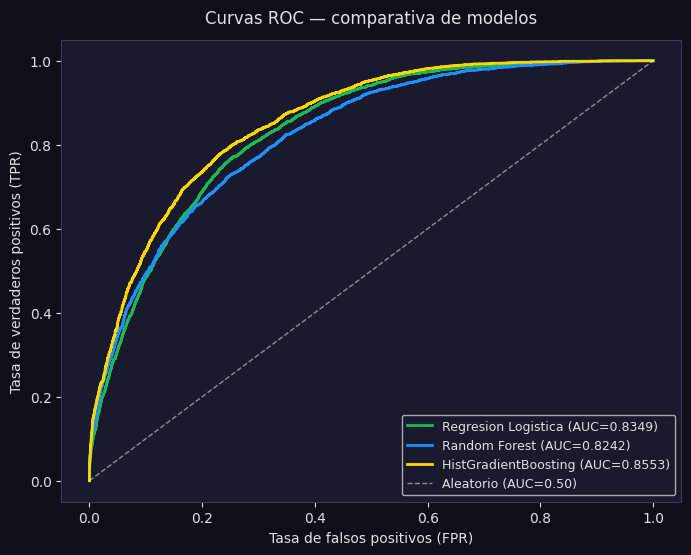

[graficos] Guardado: output\graficos\08_curvas_roc.png


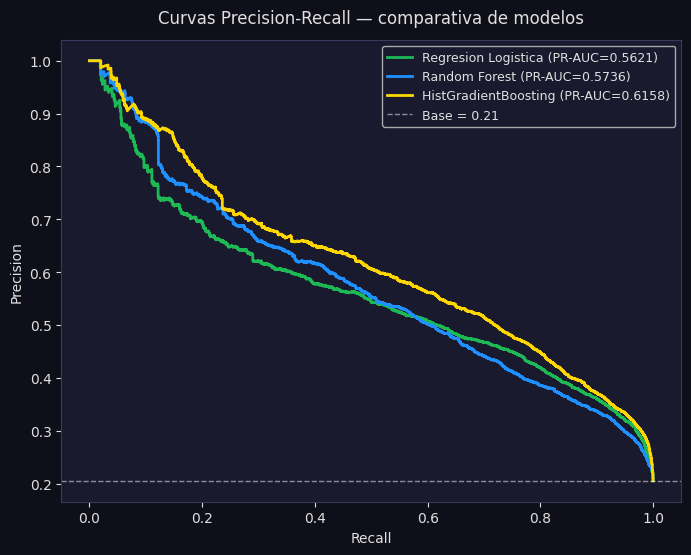

[graficos] Guardado: output\graficos\09_curvas_pr.png


In [5]:
gr.grafico_roc(res, y_test)
gr.grafico_pr(res, y_test)

## 2. Efecto del umbral de decisión
El recall depende del umbral. Con `class_weight="balanced"` el umbral 0.5 favorece el recall y deja pasar muchos falsos positivos. Esta tabla muestra el compromiso para el mejor modelo.

In [6]:
cv = pd.read_csv(os.path.join("output", "modelos", "resultados_cv.csv"), index_col=0)
mejor = res_train["mejor"] if "res_train" in globals() else cv["auc_cv"].idxmax()
m = modelos[mejor]
p = res[mejor]["y_proba"]
print(f"Mejor modelo (por AUC de CV): {mejor}")
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
pd.DataFrame([{"umbral": u,
               "precision": precision_score(y_test, (p >= u).astype(int), zero_division=0),
               "recall": recall_score(y_test, (p >= u).astype(int)),
               "f1": f1_score(y_test, (p >= u).astype(int)),
               "% de canciones marcadas como hit": (p >= u).mean() * 100} for u in umbrales]).set_index("umbral").round(3)

Mejor modelo (por AUC de CV): HistGradientBoosting


,precision,recall,f1,% de canciones marcadas como hit
umbral,,,,
0.3,0.315,0.967,0.475,63.015
0.4,0.353,0.923,0.511,53.641
0.5,0.427,0.823,0.562,39.625
0.6,0.557,0.614,0.584,22.658
0.7,0.653,0.394,0.491,12.386
0.8,0.792,0.188,0.303,4.870


## 3. ¿Cuánto aporta el género? (ablación)
`train.py` entrena el mejor modelo con y sin las columnas de género y devuelve el AUC de ambos. Son AUC de **validación cruzada agrupada sobre train**, no de test.

In [7]:
abl = res_train.get("ablacion_genero") if "res_train" in globals() else None
ruta_abl = os.path.join("output", "modelos", "ablacion_genero.csv")
if abl is None and os.path.exists(ruta_abl):
    a = pd.read_csv(ruta_abl, index_col=0)["valor"]
    abl = {"auc_con_genero": float(a["auc_con_genero"]), "auc_sin_genero": float(a["auc_sin_genero"])}
if abl:
    print(f"AUC de CV con género: {abl['auc_con_genero']:.4f} | sin género: {abl['auc_sin_genero']:.4f} | aporte del género: {abl['auc_con_genero'] - abl['auc_sin_genero']:+.4f}")
else:
    print("Ejecuta la primera celda de este notebook (o python -m src.train) para obtener la ablación.")

AUC de CV con género: 0.8569 | sin género: 0.6948 | aporte del género: +0.1620


## 4. Recall por género
Revisa si el modelo detecta hits de forma pareja entre géneros o si solo acierta en los géneros con muchos hits.

In [8]:
pred = (p >= 0.5).astype(int)
por_gen = gr.tabla_recall_por_genero(raw_test, y_test, pred)
elegibles = por_gen[por_gen.hits >= 20].dropna(subset=["recall"])
print(f"Géneros con al menos 20 hits en test: {len(elegibles)} de {len(por_gen)}")
print(f"Recall por género: mínimo {elegibles.recall.min():.2f} | mediana {elegibles.recall.median():.2f} | máximo {elegibles.recall.max():.2f}")
pd.concat([elegibles.sort_values("recall").head(8), elegibles.sort_values("recall").tail(8)]).round(2)

Géneros con al menos 20 hits en test: 74 de 114
Recall por género: mínimo 0.00 | mediana 0.88 | máximo 1.00


,n,hits,recall,precision
genero,,,,
j-dance,207.0,23.0,0.00,0.00
cantopop,200.0,25.0,0.24,0.29
sertanejo,222.0,33.0,0.30,0.14
pagode,217.0,24.0,0.33,0.25
jazz,177.0,21.0,0.33,0.26
death-metal,199.0,35.0,0.34,0.40
dubstep,208.0,29.0,0.38,0.15
r-n-b,238.0,33.0,0.45,0.50
pop-film,191.0,178.0,1.00,0.93


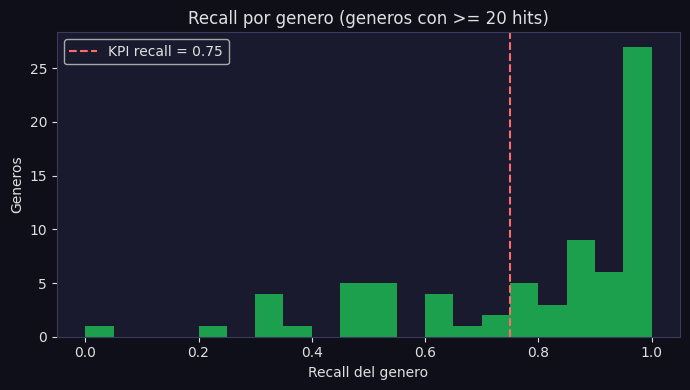

[graficos] Guardado: output\graficos\13_recall_por_genero.png


In [9]:
gr.grafico_recall_por_genero(elegibles)

## 5. Importancia de variables (permutación)
Se permuta cada variable en test y se mide cuánto cae el AUC. Las columnas de género se permutan **juntas, como un solo bloque**: permutarlas una a una no tiene sentido porque cada una es solo un 0/1 de un género.

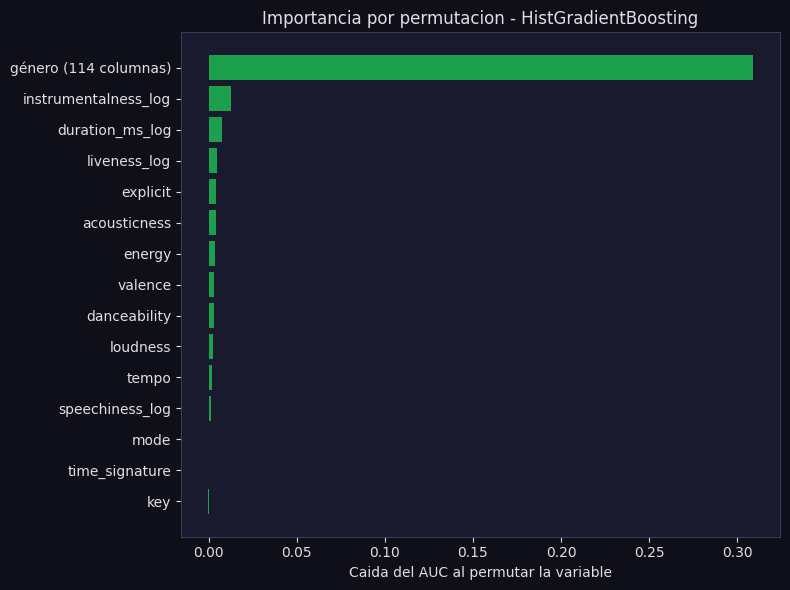

[graficos] Guardado: output\graficos\14_importancia_permutacion.png


,caída AUC
género (114 columnas),0.3088
instrumentalness_log,0.0124
duration_ms_log,0.0077
liveness_log,0.0050
explicit,0.0044


In [10]:
imp = gr.tabla_importancia_permutacion(m, X_test, y_test)
gr.grafico_importancia_permutacion(imp, mejor)
imp.sort_values(ascending=False).head(5).round(4).to_frame("caída AUC")

## 6. K-Means (no supervisado)
Se agrupan las canciones solo por sus variables de audio (sin género ni target) y luego se mira si los clusters se asocian con el hit rate.

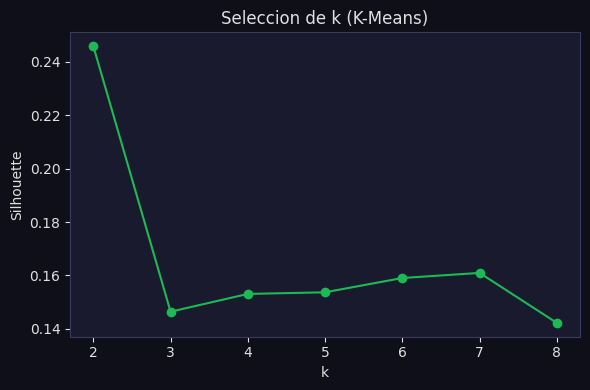

[graficos] Guardado: output\graficos\15_kmeans_silhouette.png
k elegido por silhouette: 2 (silhouette = 0.246)


In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_train[FEATURES_SCALE])
Xk_tr, Xk_te = sc.transform(X_train[FEATURES_SCALE]), sc.transform(X_test[FEATURES_SCALE])

sil = gr.silhouette_kmeans(Xk_tr)
k_opt = gr.grafico_kmeans_silhouette(sil)
print(f"k elegido por silhouette: {k_opt} (silhouette = {sil[k_opt]:.3f})")

In [12]:
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(Xk_tr)
perfil = (X_test[["danceability", "energy", "acousticness", "valence", "loudness"]]
          .assign(cluster=km.predict(Xk_te), hit=y_test.values))
res_km = perfil.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"),
                                       danceability=("danceability", "mean"), energy=("energy", "mean"),
                                       acousticness=("acousticness", "mean"), valence=("valence", "mean"),
                                       loudness=("loudness", "mean")).round(3)
print(f"Hit rate base en test: {y_test.mean():.3f}")
res_km

Hit rate base en test: 0.205


,n,hit_rate,danceability,energy,acousticness,valence,loudness
cluster,,,,,,,
0,13618,0.210,0.595,0.749,0.189,0.521,-6.450
1,4411,0.191,0.462,0.295,0.756,0.314,-14.665


## Cómo leer estos resultados

- **KPIs:** el cumplimiento de AUC, gap, recall y lift está en la tabla de la sección 1. El recall se evalúa con umbral 0.5; la sección 2 muestra cómo cambia con otro umbral.
- **Selección del modelo:** el mejor modelo se elige por AUC de validación cruzada agrupada (`src/train.py`); el conjunto de test se usa solo para el reporte final.
- **Género:** el aporte de la ablación (sección 3) y el recall por género (sección 4) son los datos para la discusión de sesgos del informe.
- **K-Means:** si los clusters de audio muestran poca diferencia de hit rate respecto a la base, la señal de audio por sí sola es débil, lo que es coherente con las correlaciones del EDA.